## Introducción

Este cuaderno calcula la **curva teórica analítica** de referencia para la función de correlación Nano-NMR en el límite de difusión en espacio semi-infinito. Se evalúa la expresión cerrada en términos de `erfc` y potencias de $\tau$:

$$G(\tau) = \frac{4}{\sqrt{\pi}}\left[\tau^{-3/2} - \frac{3}{2}\tau^{-1/2} + \frac{\sqrt{\pi}}{4} + \cdots + \frac{\sqrt{\pi}}{\sqrt{\tau}}\,\text{erfc}(\tau^{-1/2})\,e^{-1/\tau}\left(-\tau^{-3/2} + \cdots\right)\right],$$

con tiempo adimensional $\tau = D_\text{eff}\,t/d^2$.

Los parámetros físicos ($d = 15\,\text{nm}$, $L = R = 100d$) y el perfil $D(z)$ del TFM se usan para calcular $D_\text{eff}$ como promedio armónico inverso. Esta curva sirve como referencia teórica para validar los resultados numéricos del método espectral modal, verificando los asintóticos $\tau^{-3/2}$ a tiempos largos y $\tau^{-3/2}$ (divergencia) a tiempos cortos.

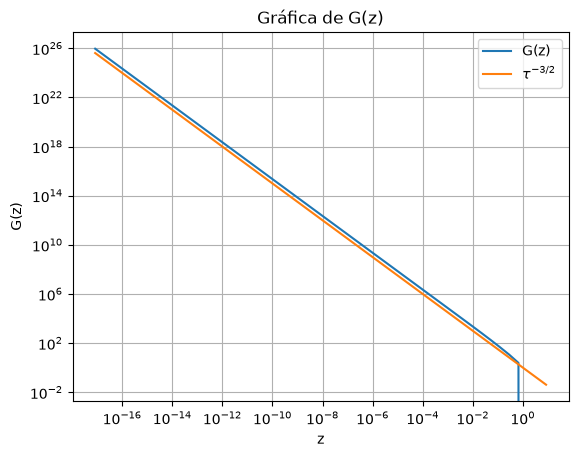

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

Nr, Nz    = 5000, 10000
alpha     = 2.0
d         = 15
L = R = 100*d # [nm]
j_idx     = np.arange(Nz+1)
z_edges   = d + L * np.sinh(alpha*j_idx/Nz) / np.sinh(alpha)  # bordes

D0, Ds    = 2e3, 2e1    # nm^2/μs
lambda_p  = 0.75/d
delta     = 2*d/3
z_c       = 0.75*L

def D_of_z(z):
    S = 0.5*(1 + np.tanh((z - (z_c + d))/delta))
    return Ds + (D0-Ds)*((1 - np.exp(-lambda_p*(z-d)))*(1-S) + S)

D_values = D_of_z(z_edges)

D_eff = L/np.trapezoid(1/D_values,z_edges)

def G(z):
    sqrt_pi = np.sqrt(np.pi)
    term1 = z**(-3/2) - (3/2) * z**(-1/2) + sqrt_pi / 4 + 3 * np.sqrt(z) - (3 * sqrt_pi / 2) * z
    term2 = (np.sqrt(np.pi) / np.sqrt(z)) * erfc(z**(-1/2)) * np.exp(-1 / z)
    term3 = -z**(-3/2) + z**(-1/2) - (7/4) * np.sqrt(z) + (3/2) * z**(3/2)
    
    return (4 / sqrt_pi) * (term1 + term2 * term3)

# Graficar G(z)
times = np.logspace(-18, 0)
tau_vals = D_eff/d**2*times
g_vals = G(tau_vals)

plt.loglog(tau_vals, g_vals, label='G(z)')
plt.loglog(tau_vals,tau_vals**(-3/2),label=r"$\tau^{-3/2}$")
plt.xlabel('z')
plt.ylabel('G(z)')
plt.title('Gráfica de G(z)')
plt.grid(True)
plt.legend()
plt.show()

## Conclusiones

La curva teórica analítica confirma los dos regímenes asintóticos esperados para la función de correlación Nano-NMR:

- A tiempos cortos ($\tau \ll 1$): la función $G(\tau)$ diverge como $\tau^{-3/2}$, señal de que las moléculas aún no han difundido hacia regiones lejanas del NV.
- A tiempos largos ($\tau \gg 1$): la correlación decae como $\tau^{-3/2}$, el comportamiento universal de la difusión tridimensional en espacio libre.

Esta curva constituye la referencia de validación para los resultados numéricos del método espectral modal implementado en `TFM_V5.ipynb`. La concordancia entre ambas en los regímenes asintóticos confirma la corrección de la implementación numérica. La difusividad efectiva $D_\text{eff}$ calculada aquí como promedio armónico de $1/D(z)$ es la misma que se usa en los cuadernos de barrido paramétrico para definir el tiempo adimensional $\tau$.